# Interactive IIR Filter Lab — poles, zeros, and sound

**Goal.** Explore IIR filters in the spirit of Georgia Tech's **PeZ / Filter Design demos**: move poles and zeros, see the z-plane, frequency response and impulse response update together, **and listen to the result of filtering a sound**.

This notebook has **two complementary interactive demonstrations**:

1. **Pole–zero editor (PeZ-style):** construct first- or second-order IIR filters by adjusting poles and zeros. With the optional `ipympl` backend, **drag the × (poles) and ○ (zeros)** directly in the z-plane.
2. **Butterworth designer:** choose low-pass, high-pass, band-pass, or band-stop, change the order and cutoff frequency, and compare the results.

Both sections work with **white noise, a square wave, a mixture of sinusoids, or your own WAV file**. They display the pole–zero plot, magnitude and phase responses, impulse response, input/output waveforms, and input/output spectra. Use **Update audio players** after changing parameters to hear the latest input/output signals.

**Prerequisites:** Jupyter Notebook, JupyterLab, or VS Code with a working Python notebook kernel. Run the cells in order. For draggable plots use Jupyter with `ipympl`; if this is unavailable, the sliders still work and plots refresh after each change.

## 0 · Set up the environment

If required, uncomment and execute the installation line below, then restart the kernel. `ipywidgets` supplies the controls and `ipympl` enables direct dragging in the plot. **Without `ipympl`, all controls still work, but pole–zero dragging is disabled.**

In [1]:
# Uncomment if any package is missing, then restart the notebook kernel:
# %pip install numpy scipy matplotlib ipywidgets ipympl ipython

In [2]:
import io
import warnings
import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import display, Audio, HTML, clear_output
import ipywidgets as widgets

# Enable live matplotlib dragging when ipympl is available.
try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic('matplotlib', 'widget')
    CAN_DRAG = True
except (ImportError, RuntimeError, ValueError):
    get_ipython().run_line_magic('matplotlib', 'inline')
    CAN_DRAG = False
import matplotlib.pyplot as plt

print('Ready. Draggable z-plane:', 'enabled' if CAN_DRAG else 'disabled (sliders remain interactive)')

Ready. Draggable z-plane: disabled (sliders remain interactive)


## 1 · Theory: an IIR filter is a feedback system

For a causal digital filter, with \(a_0=1\), the difference equation is

\[
y[n]=\sum_{k=0}^{M} b_k x[n-k]-\sum_{k=1}^{N} a_k y[n-k].
\]

Taking z-transforms (zero initial conditions) gives

\[
Y(z)\left(1+\sum_{k=1}^{N}a_kz^{-k}\right)
=X(z)\sum_{k=0}^{M}b_kz^{-k},
\qquad
H(z)=\frac{Y(z)}{X(z)}=\frac{\sum_{k=0}^{M}b_kz^{-k}}{1+\sum_{k=1}^{N}a_kz^{-k}}.
\]

The **zeros** are roots of the numerator; the **poles** are roots of the denominator. A causal rational filter is **BIBO stable if all poles lie strictly inside the unit circle**. A zero on the unit circle forces \(H(e^{j\omega})=0\) at its angle; poles near the circle create strong resonances. The **impulse response** is obtained by filtering \(\delta[n]\), *not* by using a unit-step input.

### First-order example

\[
H(z)=G\frac{1-\alpha z^{-1}}{1-\beta z^{-1}},
\qquad y[n]=\beta y[n-1]+Gx[n]-G\alpha x[n-1].
\]

For \(G=1\), the impulse response follows immediately from the recurrence:

\[
h[0]=1,\qquad h[n]=(\beta-\alpha)\beta^{n-1},\quad n\ge 1.
\]

If \(|\beta|<1\), this tail decays. As \(|\beta|\) approaches 1, it decays more slowly. The next cell verifies this formula numerically.

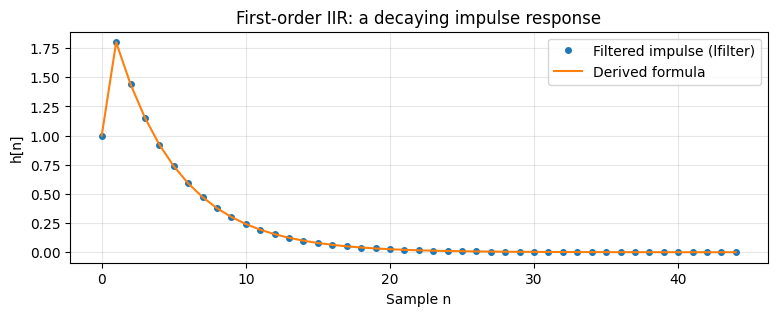

In [3]:
# Analytical impulse response versus scipy.signal.lfilter
alpha, beta = -1.0, 0.8   # zero = -1, pole = +0.8
b1 = np.array([1.0, -alpha])
a1 = np.array([1.0, -beta])
n = np.arange(45)
impulse = np.r_[1., np.zeros(len(n)-1)]
h_numeric = signal.lfilter(b1, a1, impulse)
h_formula = np.r_[1., (beta-alpha)*beta**np.arange(len(n)-1)]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(n, h_numeric, 'o', ms=4, label='Filtered impulse (lfilter)')
ax.plot(n, h_formula, '-', label='Derived formula')
ax.set(xlabel='Sample n', ylabel='h[n]', title='First-order IIR: a decaying impulse response')
ax.grid(alpha=.3); ax.legend(); plt.show()
assert np.allclose(h_numeric, h_formula)

### Conjugate pole–zero pairs (second-order IIR)

For a second-order filter with a complex-conjugate zero pair \(r_z e^{\pm j\theta_z}\) and pole pair \(r_p e^{\pm j\theta_p}\),

\[
H(z)=G\,\frac{1-2r_z\cos\theta_z\,z^{-1}+r_z^2z^{-2}}
{1-2r_p\cos\theta_p\,z^{-1}+r_p^2z^{-2}}.
\]

The pole **angle** primarily controls resonant frequency and its **radius** controls decay/resonance sharpness. Unit-circle zeros create spectral nulls. Keeping conjugate pairs together guarantees real filter coefficients. In the interactive tool, pole radii are limited to 0.995 to keep the filter stable.

The gain normalization choice is independent of pole and zero placement: it rescales \(H(z)\) so its magnitude is 1 at DC, Nyquist, or the maximum response (or leaves gain unchanged).

## 2 · Reusable audio and visualization functions

The white noise is generated with a fixed random seed so comparisons are reproducible. For a square wave, look for attenuation of its higher odd harmonics when applying a low-pass filter. The plots use \(\omega/\pi\) along the frequency axis, where 1 corresponds to Nyquist (\(f_s/2\)).

In [4]:
DEFAULT_FS = 8000
MAX_WAV_SECONDS = 3.0


def read_uploaded_wav(upload_value):
    """Handle the FileUpload value shape of both ipywidgets 7 and 8."""
    if not upload_value:
        return None
    if isinstance(upload_value, dict):             # ipywidgets 7
        first = next(iter(upload_value.values()))
    else:                                            # ipywidgets 8
        first = upload_value[0]
    data = first['content']
    fs, x = wavfile.read(io.BytesIO(bytes(data)))
    # Convert PCM to [-1,1] BEFORE stereo-to-mono averaging (preserve dtype info).
    if x.dtype.kind == 'u' and x.dtype.itemsize == 1:
        x = (x.astype(np.float64)-128.0)/128.0
    elif x.dtype.kind in 'iu':
        full_scale = float(2**(8*x.dtype.itemsize-1))
        x = x.astype(np.float64)/full_scale
    else:
        x = x.astype(np.float64)
    if x.ndim == 2:
        x = x.mean(axis=1)
    x = np.nan_to_num(x[:int(MAX_WAV_SECONDS*fs)])
    if len(x) == 0:
        raise ValueError('The WAV file is empty.')
    return fs, x


def make_source(kind, duration=1.0, tone_hz=220., seed=5, uploaded=None):
    """Produce one input x[n] and its sampling rate."""
    if kind == 'Uploaded WAV':
        wav = read_uploaded_wav(uploaded)
        if wav is not None:
            return (*wav, 'Using first %.1f s of WAV (at its original rate).' % MAX_WAV_SECONDS)
        kind = 'White noise'
        note = 'No WAV selected; showing white noise instead.'
    else:
        note = ''
    fs = DEFAULT_FS
    n = max(100, int(fs*duration))
    t = np.arange(n)/fs
    if kind == 'White noise':
        x = .25*np.random.default_rng(seed).standard_normal(n)
    elif kind == 'Square wave':
        x = .45*signal.square(2*np.pi*tone_hz*t)
    elif kind == 'Tone mixture':
        x = (.28*np.sin(2*np.pi*tone_hz*t) + .20*np.sin(2*np.pi*3*tone_hz*t)
             + .13*np.sin(2*np.pi*5*tone_hz*t))
    else:
        raise ValueError('Unknown source: '+kind)
    return fs, np.asarray(x, float), note


def coeffs_from_roots(zeros, poles, normalize='DC'):
    """Roots in z-plane -> polynomial coefficients in z^(-1). Equal root counts used here."""
    zeros, poles = np.asarray(zeros, complex), np.asarray(poles, complex)
    if len(zeros) != len(poles):
        raise ValueError('Editor uses equal numbers of poles and zeros.')
    if np.any(np.abs(poles) >= 1.0):
        raise ValueError('IIR filter must have poles strictly inside the unit circle.')
    b = np.asarray(np.real_if_close(np.poly(zeros)), float)
    a = np.asarray(np.real_if_close(np.poly(poles)), float)
    w, h = signal.freqz(b, a, worN=4096)
    if normalize == 'DC':
        ref = abs(h[0])
    elif normalize == 'Nyquist':
        ref = abs(h[-1])
    elif normalize == 'Peak':
        ref = max(abs(h))
    else:
        ref = 1.0
    if ref < 1e-9:
        return b, a, 'Normalization skipped: zero response at the chosen reference.'
    return b/ref, a, ''


def polynomial_string(coefs):
    bits = []
    for k, c in enumerate(coefs):
        if abs(c) < 5e-6:
            continue
        term = f'{abs(c):.4g}' + ('' if k == 0 else (' z⁻¹' if k == 1 else f' z⁻{k}'))
        bits.append(('-' if c < 0 else '+', term))
    if not bits:
        return '0'
    out = ('-' if bits[0][0] == '-' else '') + bits[0][1]
    return out + ''.join(f' {sign} {term}' for sign, term in bits[1:])


def spectrum_db(x, fs):
    f, pxx = signal.welch(x, fs=fs, nperseg=min(2048, len(x)))
    return f/(fs/2.), 10*np.log10(np.maximum(pxx, 1e-13))


def plot_all(fig, axs, *, zeros, poles, b, a, fs, x, y, title, sos=None):
    """Six synchronized views: z, magnitude, impulse, phase, waveform, spectra."""
    for ax in axs.flat:
        ax.clear()

    # z-plane: a dashed unit circle, zeros (o) and poles (x)
    ax = axs[0, 0]
    theta = np.linspace(0, 2*np.pi, 300)
    ax.plot(np.cos(theta), np.sin(theta), '--', lw=1, alpha=.7, label='Unit circle')
    ax.axhline(0, lw=.7, alpha=.5)
    ax.axvline(0, lw=.7, alpha=.5)
    for i, z in enumerate(zeros):
        ax.plot(z.real, z.imag, 'o', fillstyle='none', ms=11, mew=2,
                label='Zero ○' if i == 0 else None)
    for i, p in enumerate(poles):
        ax.plot(p.real, p.imag, 'x', ms=11, mew=2,
                label='Pole ×' if i == 0 else None)
    ax.set(xlim=(-1.65, 1.65), ylim=(-1.65, 1.65), xlabel='Re{z}', ylabel='Im{z}',
           title='z-plane (drag ○ / × if enabled)')
    ax.set_aspect('equal', adjustable='box')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=.25)

    if sos is None:
        w, h = signal.freqz(b, a, worN=2048)
        imp = signal.lfilter(b, a, np.r_[1., np.zeros(127)])
    else:
        w, h = signal.sosfreqz(sos, worN=2048)
        imp = signal.sosfilt(sos, np.r_[1., np.zeros(127)])

    axs[0,1].plot(w/np.pi, 20*np.log10(np.maximum(np.abs(h), 1e-7)))
    axs[0,1].set(title='Magnitude response', xlabel='Normalized frequency ω/π',
                 ylabel='20 log₁₀ |H| (dB)', xlim=(0, 1))
    axs[0,1].grid(alpha=.25)

    axs[1,0].plot(np.arange(len(imp)), imp, marker='.', ms=3)
    axs[1,0].set(title='Impulse response h[n] (first 128 samples)',
                 xlabel='Sample n', ylabel='h[n]', xlim=(0, 127))
    axs[1,0].grid(alpha=.25)

    axs[1,1].plot(w/np.pi, np.unwrap(np.angle(h)))
    axs[1,1].set(title='Unwrapped phase response', xlabel='Normalized frequency ω/π',
                 ylabel='Phase (radians)', xlim=(0, 1))
    axs[1,1].grid(alpha=.25)

    # The first 60 ms, or the full signal if it is shorter.
    nview = min(len(x), max(100, int(.06*fs)))
    t = 1000*np.arange(nview)/fs
    axs[2,0].plot(t, x[:nview], label='Input', alpha=.75)
    axs[2,0].plot(t, y[:nview], label='Output', alpha=.85)
    axs[2,0].set(title='Time-domain signal', xlabel='Time (ms)', ylabel='Amplitude')
    axs[2,0].legend(fontsize=8)
    axs[2,0].grid(alpha=.25)

    freq_in, db_in = spectrum_db(x, fs)
    freq_out, db_out = spectrum_db(y, fs)
    axs[2,1].plot(freq_in, db_in, label='Input', alpha=.8)
    axs[2,1].plot(freq_out, db_out, label='Output', alpha=.8)
    axs[2,1].set(title='Input/output power spectrum (Welch)',
                 xlabel='Normalized frequency ω/π', ylabel='Power/Hz (dB)', xlim=(0, 1))
    axs[2,1].legend(fontsize=8)
    axs[2,1].grid(alpha=.25)

    fig.suptitle(title, fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, .975), h_pad=2.0, w_pad=1.8)
    fig.canvas.draw_idle()


def audio_players(x, y, fs):
    """Use the SAME scaling for input and output so loudness remains comparable."""
    scale = max(1.0, float(np.max(np.abs(x))), float(np.max(np.abs(y))))
    display(HTML('<b>Input</b> (common playback scale for fair comparison)'))
    display(Audio(x/scale, rate=fs, normalize=False))
    display(HTML('<b>Filtered output</b>'))
    display(Audio(y/scale, rate=fs, normalize=False))
    if scale > 1.0:
        display(HTML('<small>Both signals divided by %.3g to avoid clipping on playback.</small>' % scale))


def graph_widget(fig):
    """Return widget canvas for ipympl or an Output widget for inline fallback."""
    return fig.canvas if CAN_DRAG else widgets.Output()


def update_graph(fig, holder):
    if CAN_DRAG:
        fig.canvas.draw_idle()
    else:
        with holder:
            clear_output(wait=True)
            display(fig)

## 3 · PeZ-style interactive pole–zero designer

**Try the presets first.** The first-order example has one real pole and zero; the second-order examples use a conjugate pair of each. Use the sliders, or, with `ipympl`, **click a plotted ○ or × and drag**; the paired complex-conjugate root moves automatically. Poles stay inside the unit circle; zeros may move outside it.

- **Low-pass:** zeros at \(z=-1\) suppress frequencies near Nyquist.
- **High-pass:** zeros at \(z=1\) suppress DC.
- **Resonator:** a pole pair close to the unit circle produces a narrow peak.
- **Notch:** a zero pair on the circle creates a deep null; nearby poles sharpen it.
- **All-pass:** reciprocal-conjugate pole/zero locations produce nearly flat magnitude but nontrivial phase.

The output uses **`scipy.signal.lfilter`** to implement the actual feedback difference equation. The currently used numerator and denominator coefficients are shown below the graph.

In [5]:
class SourceControls:
    """Small reusable input selector, independent for each lab."""
    def __init__(self):
        self.kind = widgets.Dropdown(
            options=['White noise', 'Square wave', 'Tone mixture', 'Uploaded WAV'],
            value='Square wave', description='Input:', layout=widgets.Layout(width='290px'))
        self.f0 = widgets.FloatSlider(value=220, min=60, max=800, step=10,
                                       description='Tone (Hz):', continuous_update=False,
                                       layout=widgets.Layout(width='320px'))
        self.duration = widgets.FloatSlider(value=1.0, min=.4, max=3.0, step=.2,
                                             description='Duration (s):', continuous_update=False,
                                             layout=widgets.Layout(width='320px'))
        self.seed = widgets.IntSlider(value=5, min=1, max=100, step=1,
                                       description='Noise seed:', continuous_update=False,
                                       layout=widgets.Layout(width='320px'))
        self.upload = widgets.FileUpload(accept='.wav', multiple=False,
                                          description='Choose WAV')
        self.ui = widgets.VBox([
            widgets.HBox([self.kind, self.upload]),
            widgets.HBox([self.f0, self.duration, self.seed])
        ])

    def observe(self, callback):
        for control in [self.kind, self.f0, self.duration, self.seed, self.upload]:
            control.observe(callback, names='value')

    def get(self):
        try:
            return make_source(self.kind.value, self.duration.value,
                               self.f0.value, self.seed.value, self.upload.value)
        except Exception as exc:
            fs, x, _ = make_source('White noise', self.duration.value,
                                   self.f0.value, self.seed.value)
            return fs, x, f'WAV could not be read ({exc}); using white noise.'


class PeZLab:
    def __init__(self):
        self._busy = False
        self._drag_target = None
        self.source = SourceControls()
        self.preset = widgets.Dropdown(options=[
            'Custom', 'First-order low-pass', 'First-order high-pass',
            'Second-order low-pass', 'Second-order high-pass',
            'Narrow resonator', 'Notch filter', 'Second-order all-pass'],
            value='Second-order low-pass', description='Preset:',
            layout=widgets.Layout(width='300px'))
        self.mode = widgets.Dropdown(options=[('Real first order','first'),
                                              ('Conjugate-pair second order','second')],
                                     value='second', description='Order:',
                                     layout=widgets.Layout(width='320px'))
        self.norm = widgets.Dropdown(options=['DC','Nyquist','Peak','None'],
                                     value='DC', description='Scale gain:',
                                     layout=widgets.Layout(width='220px'))
        self.pr = widgets.FloatSlider(description='Real pole:', min=-.995, max=.995,
                                     step=.005, value=.7, continuous_update=False)
        self.zr = widgets.FloatSlider(description='Real zero:', min=-1.6, max=1.6,
                                     step=.01, value=-1., continuous_update=False)
        self.p_radius = widgets.FloatSlider(description='Pole radius:', min=0, max=.995,
                                            step=.005, value=.73, continuous_update=False)
        self.p_angle = widgets.FloatSlider(description='Pole angle /π:', min=0, max=1,
                                           step=.005, value=.1, continuous_update=False)
        self.z_radius = widgets.FloatSlider(description='Zero radius:', min=0, max=1.6,
                                            step=.005, value=1., continuous_update=False)
        self.z_angle = widgets.FloatSlider(description='Zero angle /π:', min=0, max=1,
                                           step=.005, value=1., continuous_update=False)
        self.first_panel = widgets.HBox([self.pr,self.zr])
        self.second_panel = widgets.VBox([
            widgets.HBox([self.p_radius,self.p_angle]),
            widgets.HBox([self.z_radius,self.z_angle])])
        self.summary = widgets.HTML()
        self.audio_out = widgets.Output()
        self.audio_btn = widgets.Button(description='Update audio players', button_style='info',
                                         icon='volume-up')
        self.audio_btn.on_click(self.play)

        with plt.ioff():
            self.fig, self.axs = plt.subplots(3, 2, figsize=(12, 10))
        self.canvas_holder = graph_widget(self.fig)
        if CAN_DRAG:
            self.fig.canvas.mpl_connect('button_press_event', self.on_press)
            self.fig.canvas.mpl_connect('motion_notify_event', self.on_drag)
            self.fig.canvas.mpl_connect('button_release_event', self.on_release)
        for c in (self.mode,self.norm,self.pr,self.zr,self.p_radius,self.p_angle,
                  self.z_radius,self.z_angle):
            c.observe(self.on_parameter_change, names='value')
        self.source.observe(self.on_parameter_change)
        self.preset.observe(self.on_preset_change, names='value')
        self.apply_preset(self.preset.value)
        self.ui = widgets.VBox([
            widgets.HTML('<h3>Move poles and zeros — inspect all three domains</h3>'),
            widgets.HBox([self.preset,self.mode,self.norm]),
            self.first_panel, self.second_panel,
            widgets.HTML('<b>Test input</b>'), self.source.ui,
            self.canvas_holder, self.summary,
            self.audio_btn, self.audio_out,
        ])
        self.redraw()

    def apply_preset(self, preset):
        if preset == 'Custom':
            return
        # tuple: mode, [pole parameters], [zero parameters], gain normalization
        presets = {
            'First-order low-pass':    ('first', (.8,), (-1.,), 'DC'),
            'First-order high-pass':   ('first', (.8,), ( 1.,), 'Nyquist'),
            'Second-order low-pass':  ('second', (.73,.12), (1.,1.), 'DC'),
            'Second-order high-pass': ('second', (.73,.88), (1.,0.), 'Nyquist'),
            'Narrow resonator':       ('second', (.965,.30), (0.,.30), 'Peak'),
            'Notch filter':           ('second', (.94,.33), (1.,.33), 'DC'),
            'Second-order all-pass':  ('second', (.8,.38), (1.25,.38), 'DC'),
        }
        self._busy = True
        mode, ps, zs, norm = presets[preset]
        self.mode.value, self.norm.value = mode, norm
        if mode == 'first':
            self.pr.value, self.zr.value = ps[0], zs[0]
        else:
            self.p_radius.value, self.p_angle.value = ps
            self.z_radius.value, self.z_angle.value = zs
        self._busy = False
        self.show_mode()

    def on_preset_change(self, change):
        if self._busy or change['new'] == 'Custom':
            return
        self.apply_preset(change['new'])
        self.redraw()

    def show_mode(self):
        self.first_panel.layout.display = '' if self.mode.value == 'first' else 'none'
        self.second_panel.layout.display = 'none' if self.mode.value == 'first' else ''

    def on_parameter_change(self, change):
        if self._busy:
            return
        # Keep preset label meaningful after any manual edit.
        self._busy = True
        self.preset.value = 'Custom'
        self._busy = False
        self.show_mode()
        self.redraw()

    def roots(self):
        if self.mode.value == 'first':
            return np.array([complex(self.zr.value)]), np.array([complex(self.pr.value)])
        p = self.p_radius.value*np.exp(1j*np.pi*self.p_angle.value)
        z = self.z_radius.value*np.exp(1j*np.pi*self.z_angle.value)
        return np.array([z,np.conj(z)]), np.array([p,np.conj(p)])

    def redraw(self):
        z, p = self.roots()
        b, a, note = coeffs_from_roots(z, p, self.norm.value)
        fs, x, source_note = self.source.get()
        y = signal.lfilter(b, a, x)
        self.audio_data = (x, y, fs)
        plot_all(self.fig, self.axs, zeros=z, poles=p, b=b, a=a,
                 fs=fs, x=x, y=y, title='Manual IIR pole–zero design')
        update_graph(self.fig, self.canvas_holder)
        pole_max = max(abs(p))
        stability = 'Stable' if pole_max < 1. else 'UNSTABLE'
        info = (
            f'<b>{stability}:</b> max |pole|={pole_max:.3f}; '
            f'sampling rate={fs:,} Hz; <b>transfer function</b><br>'
            f'<code>H(z) = ({polynomial_string(b)}) / '
            f'({polynomial_string(a)})</code><br>'
            f'<small>Difference equation: y[n] = Σ b[k]x[n−k] − Σ a[k]y[n−k], k≥1 for a. '
            f'Click the button to update sound players. {source_note} {note}</small>')
        self.summary.value = info

    def play(self, _):
        with self.audio_out:
            clear_output(wait=True)
            audio_players(*self.audio_data)

    # Live movement of plotted roots; conjugate symmetry is maintained.
    def on_press(self, event):
        if event.inaxes is not self.axs[0,0] or event.xdata is None or event.ydata is None:
            return
        z, p = self.roots()
        xy = complex(event.xdata,event.ydata)
        candidates = [('zero',u) for u in z] + [('pole',v) for v in p]
        target, dist = None, 1e6
        for name, root in candidates:
            d = abs(xy-root)
            if d < dist:
                target, dist = name, d
        self._drag_target = target if dist < .18 else None

    def on_drag(self, event):
        if self._drag_target is None or event.inaxes is not self.axs[0,0]:
            return
        if event.xdata is None or event.ydata is None:
            return
        self._move_root(self._drag_target, event.xdata, event.ydata)

    def on_release(self, event):
        self._drag_target = None

    def _move_root(self, kind, re, im):
        self._busy = True
        if self.mode.value == 'first':
            target = self.pr if kind == 'pole' else self.zr
            target.value = float(np.clip(re, target.min, target.max))
        else:
            radius = float(np.hypot(re, im))
            angle = float(np.arctan2(abs(im), re)/np.pi)
            radius_slider = self.p_radius if kind == 'pole' else self.z_radius
            angle_slider = self.p_angle if kind == 'pole' else self.z_angle
            radius_slider.value = float(np.clip(radius, radius_slider.min, radius_slider.max))
            angle_slider.value = float(np.clip(angle, 0, 1))
        self.preset.value = 'Custom'
        self._busy = False
        self.redraw()

pez_lab = PeZLab()
display(pez_lab.ui)

## 4 · Design higher-order Butterworth IIR filters

Unlike the manual root editor, this uses **`scipy.signal.butter`** to design filters from specifications. Change **filter type**, **order**, and **cutoff frequency** (as a fraction of Nyquist), then compare the automatic pole–zero locations to what you saw above. The implementation uses **second-order sections (SOS)** with `sosfilt` for better numerical stability at higher orders.

For a band-pass or band-stop filter, the two cutoff settings define a frequency band; the resulting digital filter has order \(2N\) for an entered Butterworth prototype order \(N\).

In [ ]:
class ButterworthLab:
    def __init__(self):
        self.source = SourceControls()
        self.kind = widgets.Dropdown(options=[('Low-pass','lowpass'),
                                              ('High-pass','highpass'),
                                              ('Band-pass','bandpass'),
                                              ('Band-stop','bandstop')],
                                      description='Filter type:', value='lowpass',
                                      layout=widgets.Layout(width='270px'))
        self.order = widgets.IntSlider(value=3, min=1, max=10, step=1,
                                       description='Order N:', continuous_update=False)
        self.c1 = widgets.FloatSlider(value=.2, min=.02, max=.98, step=.01,
                                      description='Cutoff 1:', continuous_update=False)
        self.c2 = widgets.FloatSlider(value=.55, min=.02, max=.98, step=.01,
                                      description='Cutoff 2:', continuous_update=False)
        self.summary = widgets.HTML()
        self.audio_out = widgets.Output()
        self.audio_btn = widgets.Button(description='Update audio players', button_style='info',
                                        icon='volume-up')
        self.audio_btn.on_click(self.play)
        with plt.ioff():
            self.fig, self.axs = plt.subplots(3, 2, figsize=(12, 10))
        self.canvas_holder = graph_widget(self.fig)
        for ctrl in [self.kind, self.order, self.c1, self.c2]:
            ctrl.observe(self.on_change, names='value')
        self.source.observe(self.on_change)
        self.ui = widgets.VBox([
            widgets.HTML('<h3>Butterworth IIR design from specifications</h3>'),
            widgets.HBox([self.kind,self.order]),
            widgets.HBox([self.c1,self.c2]),
            widgets.HTML('<small>Cutoffs are fractions of Nyquist (0–1). '
                         'For band filters cutoff 1 must be below cutoff 2.</small>'),
            widgets.HTML('<b>Test input</b>'), self.source.ui,
            self.canvas_holder, self.summary,
            self.audio_btn, self.audio_out,
        ])
        self.on_change(None)

    def on_change(self, change):
        btype = self.kind.value
        self.c2.disabled = btype in ('lowpass','highpass')
        if btype in ('bandpass','bandstop'):
            lo, hi = sorted((self.c1.value, self.c2.value))
            if hi-lo < .02:
                hi = min(.99, lo+.02)
            cutoff = [lo,hi]
        else:
            cutoff = self.c1.value
        sos = signal.butter(self.order.value, cutoff, btype=btype, output='sos')
        z, p, gain = signal.sos2zpk(sos)
        # b/a for inspecting coefficients (actual filtering still uses SOS).
        b, a = signal.sos2tf(sos)
        fs, x, source_note = self.source.get()
        y = signal.sosfilt(sos, x)
        self.audio_data = (x,y,fs)
        plot_all(self.fig, self.axs, zeros=z, poles=p, b=b, a=a,
                 fs=fs, x=x, y=y, title=f'Butterworth {btype} (prototype order {self.order.value})',
                 sos=sos)
        update_graph(self.fig, self.canvas_holder)
        cutlabel = ', '.join(f'{c:.2f}' for c in cutoff) if isinstance(cutoff,list) else f'{cutoff:.2f}'
        hz = [c*fs/2 for c in cutoff] if isinstance(cutoff,list) else [cutoff*fs/2]
        filt_order = len(p)
        self.summary.value = (
            f'<b>Filter order:</b> {filt_order} · <b>Cutoff/Nyquist:</b> {cutlabel} · '
            f'<b>Cutoff in Hz:</b> {", ".join(f"{v:.0f}" for v in hz)} · '
            f'<b>max |pole|:</b> {max(abs(p)):.4f} (stable) · '
            f'<b>SOS stages:</b> {len(sos)}<br>'
            f'<small>Direct-form coefficients: b={np.array2string(b, precision=4, suppress_small=True)}, '
            f'a={np.array2string(a, precision=4, suppress_small=True)}. '
            f'Actual filtering uses SOS. {source_note}</small>')

    def play(self, _):
        with self.audio_out:
            clear_output(wait=True)
            audio_players(*self.audio_data)

butter_lab = ButterworthLab()
display(butter_lab.ui)

## 5 · Suggested classroom experiments

1. **First-order low-pass:** set the pole to \(0.2\), then to \(0.9\), while leaving the zero at \(-1\). Compare the magnitude response and the number of samples over which \(h[n]\) remains significant. Listen to square-wave input after filtering.
2. **First-order high-pass:** select the preset with the zero at \(z=1\). Why is the response at \(\omega=0\) exactly zero? What happens to the low-frequency components of the square wave?
3. **Resonance:** select **Narrow resonator**, move the pole angle from \(0.3\pi\) to \(0.6\pi\), and then increase pole radius from \(0.8\) to \(0.98\). Compare the center frequency, bandwidth, and impulse-response decay.
4. **Notch filtering:** keep both zeros *on* the unit circle and make their angle \(\theta_z=0.33\pi\). Change the pole radius and listen to white noise. Why does the notch become narrower when the poles approach the circle?
5. **All-pass:** select **Second-order all-pass**. Check that the magnitude is approximately constant even though the impulse response and phase change. Compare input/output of a square wave.
6. **Butterworth order:** choose a low-pass with cutoff \(0.2\times\) Nyquist and compare orders 1, 3, and 8. Notice how the transition band changes and how many poles appear. Repeat with white noise.
7. **Band-pass:** choose band-pass with cutoffs 0.20 and 0.35, then vary the order. Observe how the broad spectrum of white noise becomes restricted to one band.

### Questions to ask students

- Why do **unit-circle zeros** create nulls in the magnitude response?
- How do **pole radius** and **pole angle** affect the impulse response and the sound?
- How are the **feedback coefficients** \(a_k\) reflected in the transfer function and pole locations?
- Why are **second-order sections** preferable when implementing a high-order IIR filter?
- What changes between an **impulse response** and a **step response**? Which is used to characterize an LTI system?

**References:** [DSP First — PeZ Demo and Filter Design Demo](https://dspfirst.gatech.edu/matlab/) · [DSP First — IIR Filters](https://dspfirst.gatech.edu/chapters/08feedbac/overview.html) · [SciPy: `butter`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html) · [SciPy: `lfilter`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lfilter.html).

*This notebook is an independent teaching implementation inspired by the behavior of the referenced MATLAB demonstrations; it does not incorporate their source code.*